# VAR and IRF Analysis

This notebook builds a Vector Autoregression (VAR) model to analyze the impulse response of Case-Shiller Home Price Indexes to a shock in the Federal Funds Rate (FFR).

**Variables:**
*   `unemp`: Unemployment Rate
*   `log(pce)`: Log of Personal Consumption Expenditures
*   `ffr`: Federal Funds Rate
*   `log(cs-indexes)`: Log of Case-Shiller Home Price Indexes

**Model Specification:**
*   Lags: 12
*   Cholesky Ordering: `unemp`, `log(pce)`, `ffr`, `log(cs-index)`
*   IRF Horizon: 48 months


In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.api import VAR

# Load the data
file_path = 'data_csv/var_data.csv'
df = pd.read_csv(file_path, index_col='Unnamed: 0')
df.index = pd.to_datetime(df.index) # Ensure index is datetime
df.index.name = 'Date'

# Display first few rows
print(df.head())
print(df.columns)

                cs       cs10     pce   ffr  unemp  pce_rate  atlanta  \
Date                                                                    
1987-01-01  63.733  63.103814  51.894  6.43    6.6      3.16      NaN   
1987-02-01  64.132  63.804972  52.076  6.10    6.6      3.22      NaN   
1987-03-01  64.468  64.425674  52.214  6.13    6.6      3.41      NaN   
1987-04-01  64.972  65.063393  52.409  6.37    6.3      3.57      NaN   
1987-05-01  65.547  65.815103  52.542  6.85    6.3      3.66      NaN   

               boston  charlotte    chicago  ...      miami  minneapolis  \
Date                                         ...                           
1987-01-01  70.266973  63.559024  54.206479  ...  68.547905          NaN   
1987-02-01  70.640678  64.028844  55.227274  ...  68.919119          NaN   
1987-03-01  71.046774  64.105242  54.811034  ...  69.388052          NaN   
1987-04-01  71.411571  64.892990  54.801947  ...  69.463461          NaN   
1987-05-01  71.882711  65.222790

In [52]:
# List of Case-Shiller index columns



# Full names for plotting
cs_cols_map = {
    'cs': 'National Home Price Index',
    'cs10': '10-City Composite Index',
    'las vegas': 'Las Vegas',
    'new york': 'New York',
    'denver': 'Denver',
    'cleveland': 'Cleveland',
    
}

cs_cols = list(cs_cols_map.keys())

# Apply Log Transformations
df['log_pce'] = np.log(df['pce'])

for col in cs_cols:
    if col in df.columns:
        df[f'log_{col}'] = np.log(df[col])
    else:
        print(f"Warning: Column '{col}' not found in dataframe.")

# Check the transformed data
cols_to_check = ['unemp', 'log_pce', 'ffr'] + [f'log_{col}' for col in cs_cols if col in df.columns]
print(df[cols_to_check].head())

            unemp   log_pce   ffr    log_cs  log_cs10  log_las vegas  \
Date                                                                   
1987-01-01    6.6  3.949203  6.43  4.154702  4.144781       4.195983   
1987-02-01    6.6  3.952704  6.10  4.160943  4.155831       4.213226   
1987-03-01    6.6  3.955351  6.13  4.166169  4.165512       4.217301   
1987-04-01    6.3  3.959078  6.37  4.173956  4.175362       4.222240   
1987-05-01    6.3  3.961613  6.85  4.182767  4.186849       4.218435   

            log_new york  log_denver  log_cleveland  
Date                                                 
1987-01-01      4.313191    3.918959       3.990046  
1987-02-01      4.331308    3.915227       3.993220  
1987-03-01      4.346880    3.919663       3.995734  
1987-04-01      4.360312    3.926806       3.991857  
1987-05-01      4.377960    3.927178       4.002342  


## Methodology

### 1. Vector Autoregression (VAR) Model
We estimate a reduced-form VAR model of order $p=12$:
$$ Y_t = c + A_1 Y_{t-1} + \dots + A_{12} Y_{t-12} + u_t $$
where $Y_t$ is a vector of endogenous variables:
$$ Y_t = [\text{Unemployment}, \log(\text{PCE}), \text{FFR}, \log(\text{CS Index})]' $$

### 2. Identification Strategy (Cholesky Decomposition)
To recover structural shocks $\varepsilon_t$ from the reduced-form residuals $u_t$, we use the Cholesky decomposition of the covariance matrix $\Sigma_u = E[u_t u_t']$:
$$ u_t = P \varepsilon_t $$
where $P$ is a lower triangular matrix. This implies a recursive ordering where variables ordered earlier affect later variables contemporaneously, but not vice-versa.

**Ordering:** `Unemployment` $\to$ `log(PCE)` $\to$ `FFR` $\to$ `log(CS Index)`

### 3. Impulse Response Function (IRF) & Error Bands
We compute the orthogonalized impulse response functions to a **one standard deviation structural shock** to the Federal Funds Rate (FFR).

**Confidence Intervals:**
Instead of Monte Carlo simulations, we use **Asymptotic Standard Errors** to generate symmetric 95% confidence intervals:
$$ CI_{95\%} = \text{IRF} \pm 1.96 \times \text{SE}_{asym} $$
This ensures the error bands are symmetric and analytically derived.

In [53]:
def run_var_analysis(df, cs_cols, start_date=None, end_date=None, lags=12, irf_steps=48):
    """
    Fits VAR models for each housing index and computes IRFs with Asymptotic SE.
    
    Args:
        df (pd.DataFrame): The main dataframe containing all variables.
        cs_cols (list): List of Case-Shiller column names to analyze.
        start_date (str or pd.Timestamp, optional): Start date for the analysis.
        end_date (str or pd.Timestamp, optional): End date for the analysis.
        lags (int): Number of lags for the VAR model.
        irf_steps (int): Number of steps for the IRF.
        
    Returns:
        dict: A dictionary containing the IRF results (response, lower, upper) for each city.
    """
    irf_results = {}
    
    # Filter data by date if provided
    data = df.copy()
    if start_date:
        data = data[data.index >= start_date]
    if end_date:
        data = data[data.index <= end_date]
        
    print(f"Analysis Period: {data.index.min().date()} to {data.index.max().date()}")
    print(f"{'Model':<10} | {'FFR Residual SD':<20} | {'FFR Cholesky Shock':<20}")
    print("-" * 60)

    for cs_col in cs_cols:
        # Define the variables for the current VAR model
        # Cholesky ordering: unemp, log(pce), ffr, log(cs-index)
        current_vars = ['unemp', 'log_pce', 'ffr', f'log_{cs_col}']
        
        # Select data
        data_subset = data[current_vars].dropna()
        
        if len(data_subset) == 0:
            print(f"Warning: No data for {cs_col} in the specified range.")
            continue

        # Initialize and fit VAR model
        model = VAR(data_subset)
        results = model.fit(lags)
        
        # Compute the standard deviation of the FFR residuals
        ffr_resid_std = results.resid['ffr'].std()
        
        # Compute Cholesky decomposition to find the structural shock size
        sigma_u = results.sigma_u
        P = np.linalg.cholesky(sigma_u)
        ffr_idx = current_vars.index('ffr')
        ffr_shock_size = P[ffr_idx, ffr_idx]
        
        print(f"{cs_col:<10} | {ffr_resid_std:.6f}             | {ffr_shock_size:.6f}")
        
        # Compute IRF
        irf = results.irf(irf_steps)
        
        # Extract the response of log(cs-index) to a shock in ffr
        cs_idx = current_vars.index(f'log_{cs_col}')
        
        # Get the Orthogonalized IRF values (Structural VAR with Cholesky)
        response = irf.orth_irfs[:, cs_idx, ffr_idx]
        
        # Get Asymptotic Standard Errors (Symmetric 95% CI)
        stderr_matrix = irf.stderr(orth=True)
        stderr = stderr_matrix[:, cs_idx, ffr_idx]
        
        # 95% CI is approx +/- 1.96 * SE
        lower = response - 1.96 * stderr
        upper = response + 1.96 * stderr
        
        irf_results[cs_col] = (response, lower, upper)
        
    return irf_results

def plot_irf_grid(irf_results, cs_names, title_suffix="", ylim=None):
    """
    Plots the IRF results in a grid with shared axes.
    
    Args:
        irf_results (dict): Dictionary containing (response, lower, upper) for each city.
        cs_names (dict): Mapping of short codes to full city names.
        title_suffix (str): Optional suffix for the plot title.
        ylim (tuple): Optional (y_min, y_max) tuple to set fixed y-axis limits.
    """
    import math
    
    if not irf_results:
        print("No results to plot.")
        return

    if ylim is None:
        # Determine global y-axis limits for comparison
        all_values = []
        for response, lower, upper in irf_results.values():
            all_values.extend([response, lower, upper])
        
        if not all_values:
            print("No data in results.")
            return
            
        all_values = np.concatenate([x.flatten() for x in all_values])

        y_min = all_values.min()
        y_max = all_values.max()
        # Add some padding
        padding = (y_max - y_min) * 0.1
        y_min -= padding
        y_max += padding
    else:
        y_min, y_max = ylim

    # Create subplots: Calculate rows based on 3 columns
    n_cols = 3
    n_rows = math.ceil(len(irf_results) / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows), sharex=True, sharey=True)
    axes = axes.flatten() # Flatten to 1D array for easy iteration

    for i, (cs_col, (response, lower, upper)) in enumerate(irf_results.items()):
        ax = axes[i]
        
        # Plot the mean response
        ax.plot(range(len(response)), response, color='tab:blue', linewidth=2)
        
        # Plot the 95% confidence interval
        ax.fill_between(range(len(response)), lower, upper, color='tab:blue', alpha=0.2)
        
        # Use full name for title
        title_name = cs_names.get(cs_col, cs_col.title())
        ax.set_title(f'Response of {title_name}')
        
        ax.axhline(0, color='black', linestyle='--', linewidth=0.8)
        ax.grid(True)
        ax.set_ylim(y_min, y_max) # Enforce same limits

    # Hide unused subplots
    for j in range(len(irf_results), len(axes)):
        fig.delaxes(axes[j])

    # Set common labels
    fig.suptitle(f'Orthogonal Impulse Response of Log Case-Shiller Indexes to FFR Shock\n{title_suffix}', fontsize=16)
    fig.text(0.5, 0.02, 'Months after Shock', ha='center', fontsize=12)
    fig.text(0.02, 0.5, 'Response (Log Price)', va='center', rotation='vertical', fontsize=12)

    plt.tight_layout(rect=[0.03, 0.03, 1, 0.95]) # Adjust layout
    plt.show()
    
    return (y_min, y_max)

In [54]:
# --- Analysis Specifications ---

# Parameters
lags = 12
irf_steps = 48

# Define the specifications for the analysis
specs = [
    {
        "name": "Original Specification",
        "start_date": "1987-01-01",
        "end_date": "2007-07-01", 
        "description": "Full sample period (1987-2007)"
    },
    {
        "name": "Robustness Check",
        "start_date": "1987-01-01",
        "end_date": "2003-07-01",
        "description": "Restricted sample period (1987-2003)"
    }
]

Running Original Specification...
Description: Full sample period (1987-2007)
Analysis Period: 1987-01-01 to 2007-07-01
Model      | FFR Residual SD      | FFR Cholesky Shock  
------------------------------------------------------------
cs         | 0.123072             | 0.134291
cs10       | 0.125683             | 0.138050


c:\Users\tuoma\Desktop\gradu_python\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\tuoma\Desktop\gradu_python\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\tuoma\Desktop\gradu_python\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


las vegas  | 0.121740             | 0.133722
new york   | 0.125748             | 0.138619
denver     | 0.124688             | 0.136920
new york   | 0.125748             | 0.138619
denver     | 0.124688             | 0.136920


c:\Users\tuoma\Desktop\gradu_python\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\tuoma\Desktop\gradu_python\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\tuoma\Desktop\gradu_python\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


cleveland  | 0.125497             | 0.137178


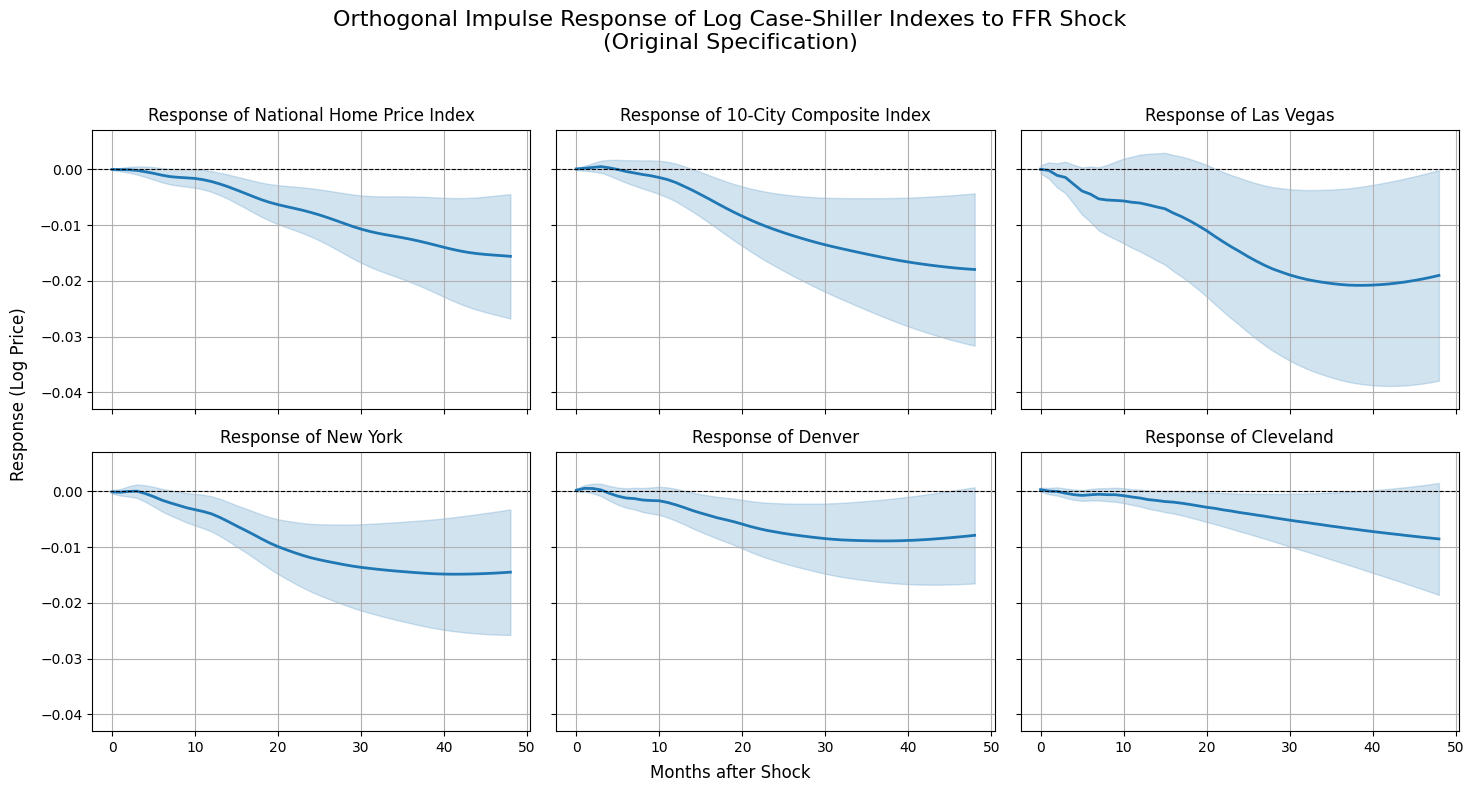

In [55]:
# --- Run Original Specification ---
spec = specs[0]
print(f"Running {spec['name']}...")
print(f"Description: {spec['description']}")

irf_results_original = run_var_analysis(
    df, 
    cs_cols, 
    start_date=spec['start_date'], 
    end_date=spec['end_date'], 
    lags=lags, 
    irf_steps=irf_steps
)

ylim_original = plot_irf_grid(
    irf_results_original, 
    cs_cols_map, 
    title_suffix=f"({spec['name']})"
)

## Robustness Check

We perform a robustness check by restricting the sample period to **1987/1 - 2003/7**. This excludes the housing bubble peak and subsequent crash, testing whether the results hold in a more stable period.

Running Robustness Check...
Description: Restricted sample period (1987-2003)
Analysis Period: 1987-01-01 to 2003-07-01
Model      | FFR Residual SD      | FFR Cholesky Shock  
------------------------------------------------------------
cs         | 0.122716             | 0.137163
cs10       | 0.129944             | 0.148014
las vegas  | 0.126260             | 0.142664


c:\Users\tuoma\Desktop\gradu_python\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\tuoma\Desktop\gradu_python\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\tuoma\Desktop\gradu_python\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\tuoma\Desktop\gradu_python\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\tuoma\Desktop\gradu_python\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarn

new york   | 0.129496             | 0.147576
denver     | 0.128052             | 0.145550
cleveland  | 0.130912             | 0.148077


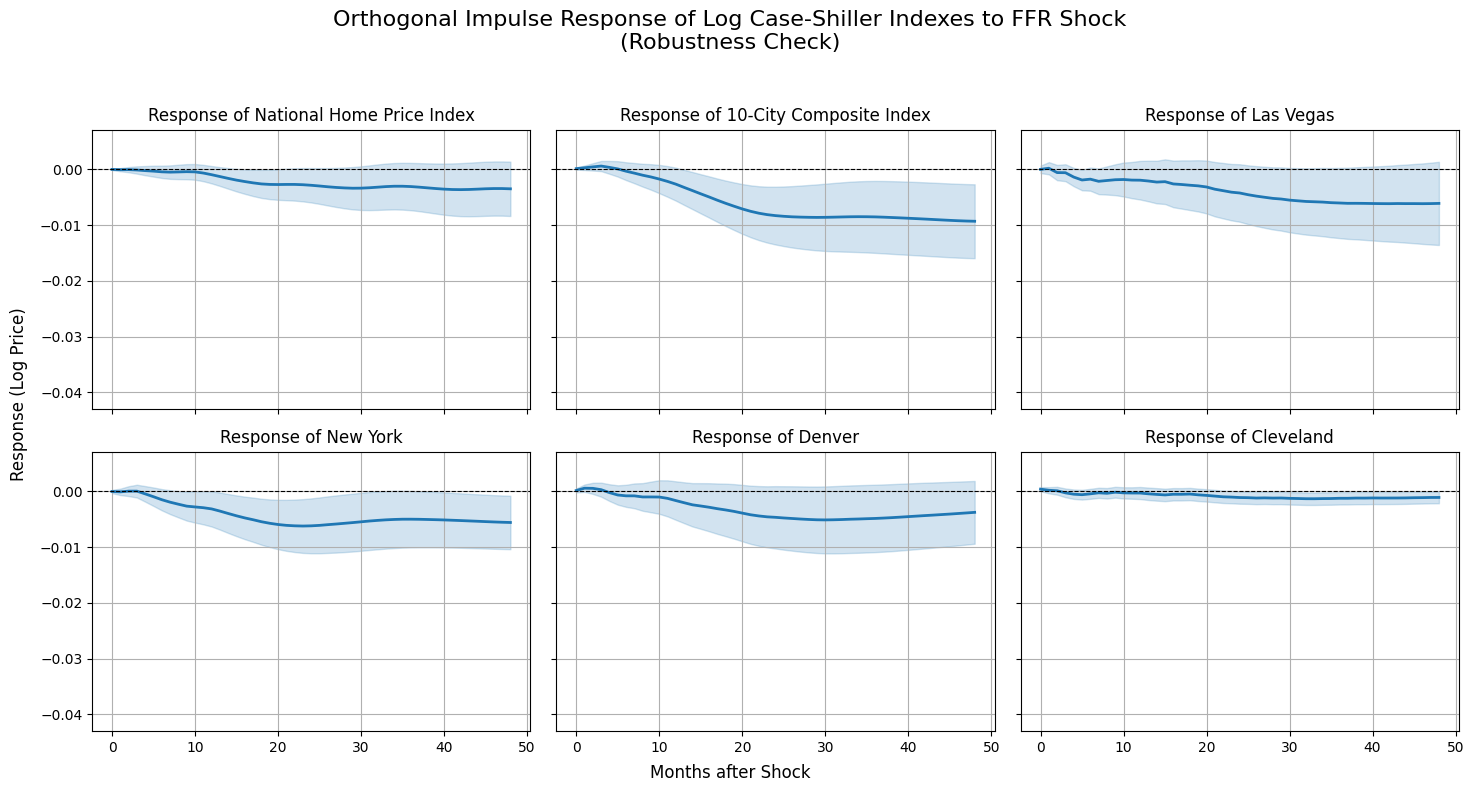

(np.float64(-0.04304898491243387), np.float64(0.007162335439323832))

In [56]:
# --- Run Robustness Check ---
spec = specs[1]
print(f"Running {spec['name']}...")
print(f"Description: {spec['description']}")

irf_results_robustness = run_var_analysis(
    df, 
    cs_cols, 
    start_date=spec['start_date'], 
    end_date=spec['end_date'], 
    lags=lags, 
    irf_steps=irf_steps
)

plot_irf_grid(
    irf_results_robustness, 
    cs_cols_map, 
    title_suffix=f"({spec['name']})",
    ylim=ylim_original
)